# Parameter Types and Querying Sweepable Parameters

:::{tip} Run interactively
Run this notebook interactively in your browser with zero installation:
- **[Open in JupyterLite Lab](/lite/lab/index.html?path=user-guide/sweep/parameter-types.ipynb)**
:::

Before running a {term}`parameter sweep`, you need to know **which** parameters a hybrid network exposes, **how** to name them in `sweep()`, and **which** parameters vary inside a single batched sweep versus an outer Python loop.

This notebook shows how to:
1. Assemble a heterogeneous two-subnetwork hybrid model (`JansenRit` cortex + `MontbrioPazoRoxin` subcortex) with both `IntraProjection` and `InterProjection` pathways.
2. Query sweepable parameters directly from the TVB hybrid API (`nb.available_sweep_params`, `_CFUN_PARAM_ATTRS`, `_NAMED_PARAM_ALIASES`, and model trait domains).
3. Validate parameter dictionaries before launching a simulation via `CppHybridBackend._resolve_sweep`.
4. Run a joint sweep across an intra-subnetwork coupling gain, an inter-subnetwork coupling parameter, and a local model excitability parameter.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

from tvb.simulator.hybrid import (
    Subnetwork,
    IntraProjection,
    InterProjection,
    NetworkSet,
)
from tvb.simulator.hybrid.coupling import Linear, Sigmoidal
from tvb.simulator.models import JansenRit, MontbrioPazoRoxin
from tvb.simulator.integrators import HeunDeterministic
from tvb.simulator.backend import hybrid_common
from tvb.simulator.backend.cpp_hybrid import notebook as nb
from tvb.simulator.backend.cpp_hybrid.backend import CppHybridBackend

## 1. Assemble a heterogeneous hybrid network

We connect an 8-node `JansenRit` cortical subnetwork (with a `Linear` `IntraProjection`) to a 6-node `MontbrioPazoRoxin` subcortical subnetwork (with a `Linear` `IntraProjection`) via a `Sigmoidal` `InterProjection`. Notice that `IntraProjection` expects integer NumPy arrays for `source_cvar` / `target_cvar`, and `JansenRit` needs bounded initial conditions (zeros below) to avoid exponential overflow on the first step.

In [2]:
dt = 0.1
n_ctx, n_sub = 8, 6
c0 = np.array([0], dtype=np.int_)
c1 = np.array([1], dtype=np.int_)

jr = JansenRit(variables_of_interest=("y0", "y1"))
jr.configure()
cortex = Subnetwork(
    name="cortex",
    model=jr,
    scheme=HeunDeterministic(dt=dt),
    nnodes=n_ctx,
)
w_ctx = sp.csr_matrix(np.full((n_ctx, n_ctx), 0.01, dtype=np.float32) * (1 - np.eye(n_ctx, dtype=np.float32)))
cortex.projections = [
    IntraProjection(
        source_cvar=c1,
        target_cvar=c0,
        weights=w_ctx,
        lengths=sp.csr_matrix((n_ctx, n_ctx), dtype=np.float32),
        cv=5.0,
        dt=dt,
        scale=1.0,
        cfun=Linear(a=np.array([0.02])),
    )
]
cortex.configure()

mpr = MontbrioPazoRoxin()
mpr.configure()
subcortex = Subnetwork(
    name="subcortex",
    model=mpr,
    scheme=HeunDeterministic(dt=dt),
    nnodes=n_sub,
)
w_sub = sp.csr_matrix(np.full((n_sub, n_sub), 0.02, dtype=np.float32) * (1 - np.eye(n_sub, dtype=np.float32)))
subcortex.projections = [
    IntraProjection(
        source_cvar=c0,
        target_cvar=c0,
        weights=w_sub,
        lengths=sp.csr_matrix((n_sub, n_sub), dtype=np.float32),
        cv=5.0,
        dt=dt,
        scale=1.0,
        cfun=Linear(a=np.array([0.1])),
    )
]
subcortex.configure()

w_inter = sp.csr_matrix(np.full((n_sub, n_ctx), 0.05, dtype=np.float32))
c2s = InterProjection(
    source=cortex,
    target=subcortex,
    source_cvar=c1,
    target_cvar=c0,
    weights=w_inter,
    lengths=sp.csr_matrix((n_sub, n_ctx), dtype=np.float32),
    cv=5.0,
    dt=dt,
    scale=1.0,
    cfun=Sigmoidal(a=np.array([0.5]), sigma=np.array([1.0]), midpoint=np.array([0.0])),
)

ns = NetworkSet(subnets=[cortex, subcortex], projections=[c2s])
ns.configure()
print("Network configured:", [sn.name for sn in ns.subnets])

Network configured: ['cortex', 'subcortex']


## 2. Querying `nb.available_sweep_params(ns)`

The helper `nb.available_sweep_params(ns)` returns a grouped dictionary of sweep keys:
- `coupling`: shorthand aliases that bind to the first matching projection {term}`coupling function` attribute.
- `projection`: inter-projection templates of the form `{source}_to_{target}.<cfun_attr>`.
- `model`: dotted `{subnet}.{param}` names for every local model parameter.

Passing an unrecognized key raises a `ValueError` listing valid suggestions automatically.

In [3]:
avail = nb.available_sweep_params(ns)
for group, items in avail.items():
    print(f"{group}: {items}")

try:
    nb.sweep(ns, 10, unknown_key=[1.0, 2.0])
except ValueError as err:
    print("\nError hint on typo:\n", err)

coupling: ['coupling_a', 'coupling_b', 'coupling_scale', 'midpoint', 'scale', 'sigma']
projection: ['cortex_to_subcortex.<cfun_attr>']
model: ['cortex.A', 'cortex.B', 'cortex.a', 'cortex.b', 'cortex.v0', 'cortex.nu_max', 'cortex.r', 'cortex.J', 'cortex.a_1', 'cortex.a_2', 'cortex.a_3', 'cortex.a_4', 'cortex.mu', 'subcortex.tau', 'subcortex.Delta', 'subcortex.eta', 'subcortex.J', 'subcortex.I', 'subcortex.cr', 'subcortex.cv']

Error hint on typo:
 Cannot resolve sweep parameter 'unknown_key'. Use 'coupling_scale', '{proj}.{attr}', or '{subnet}.{param}'. Projections: ['cortex_to_subcortex', 'cortex.intra', 'subcortex.intra']. Subnets: ['cortex', 'subcortex'].
Try one of: coupling ['coupling_a', 'coupling_b', 'coupling_scale', 'midpoint', 'scale', 'sigma']; model ['cortex.A', 'cortex.B', 'cortex.a', 'cortex.b', 'cortex.v0', 'cortex.nu_max', 'cortex.r', 'cortex.J', 'cortex.a_1', 'cortex.a_2', 'cortex.a_3', 'cortex.a_4']...; projection attrs e.g. ['cortex_to_subcortex.<cfun_attr>']


## 3. Full programmatic introspection (including `IntraProjection` and coupling attributes)

Notice two helpful details when inspecting `available_sweep_params(ns)`:
1. It prints `<cfun_attr>` as a placeholder on inter-projections rather than expanding the attributes of the attached `cfun` class.
2. It omits `IntraProjection` keys (`{subnet}.intra.{attr}`), even though the parameter resolver (`hybrid_common._resolve_named_params`) resolves them!

We can query `hybrid_common._CFUN_PARAM_ATTRS`, `hybrid_common._NAMED_PARAM_ALIASES`, each subnetwork's `projections`, and each model's `neotraits` domains to build a complete catalog—and validate any parameter dictionary ahead of execution with `CppHybridBackend._resolve_sweep`.

In [4]:
print("Supported coupling function attributes:")
for cls_name, attrs in hybrid_common._CFUN_PARAM_ATTRS.items():
    print(f"  {cls_name:18s} -> {[a for a, _ in attrs]}")

print("\nCoupling aliases:")
for alias, spec in hybrid_common._NAMED_PARAM_ALIASES.items():
    print(f"  {alias:16s} -> cfun.{spec['attr']}")


def inspect_sweepable_params(network_set):
    '''Enumerate all sweepable inter/intra projection keys and model params.'''
    catalog = {"inter_projections": [], "intra_projections": [], "models": {}}

    for proj in getattr(network_set, "projections", []) or []:
        if proj.cfun is not None:
            cls_name = type(proj.cfun).__name__
            attrs = [a for a, _ in hybrid_common._CFUN_PARAM_ATTRS.get(cls_name, [])]
            pname = f"{proj.source.name}_to_{proj.target.name}"
            catalog["inter_projections"].extend(f"{pname}.{a}" for a in attrs)

    for sn in network_set.subnets:
        for proj in getattr(sn, "projections", []) or []:
            if proj.cfun is not None:
                cls_name = type(proj.cfun).__name__
                attrs = [a for a, _ in hybrid_common._CFUN_PARAM_ATTRS.get(cls_name, [])]
                raw_name = getattr(proj, "name", None) or "intra"
                prefix = f"{sn.name}.{raw_name}" if raw_name == "intra" else raw_name
                catalog["intra_projections"].extend(f"{prefix}.{a}" for a in attrs)

        model = sn.model
        pnames = getattr(model, "global_parameter_names", None) or getattr(model, "parameter_names", None) or []
        model_cls = type(model)
        catalog["models"][sn.name] = {
            f"{sn.name}.{p}": {
                "value": np.asarray(getattr(model, p)).tolist(),
                "domain": repr(getattr(getattr(model_cls, p, None), "domain", None)),
            }
            for p in pnames
        }
    return catalog


cat = inspect_sweepable_params(ns)
print("\nInter-projection keys:", cat["inter_projections"])
print("Intra-projection keys:", cat["intra_projections"])
print("\nSubnetwork model parameters (sample):")
for sname, pdict in cat["models"].items():
    sample = list(pdict.items())[:4]
    print(f"  [{sname}] ({len(pdict)} total):", {k: v["value"] for k, v in sample})

# Dry-run validation without launching the simulation
targets, sweep_vals = CppHybridBackend._resolve_sweep(
    ns,
    {
        "cortex.intra.a": [0.01, 0.02, 0.03],
        "cortex_to_subcortex.midpoint": [-0.5, 0.0, 0.5],
        "subcortex.eta": [-5.0, -4.0, -3.0],
    },
)
print("\nResolved targets:", targets)
print("Resolved sweep_values shape:", sweep_vals.shape)

Supported coupling function attributes:
  Linear             -> ['a', 'b']
  Scaling            -> ['a']
  Sigmoidal          -> ['a', 'sigma', 'midpoint', 'cmin', 'cmax']
  SigmoidalJansenRit -> ['a', 'e0', 'r', 'v0', 'cmin', 'cmax', 'midpoint']
  Kuramoto           -> ['a', 'inv_N']
  Difference         -> ['a']
  HyperbolicTangent  -> ['a', 'midpoint', 'sigma', 'b']
  PreSigmoidal       -> ['H', 'Q', 'G', 'P', 'theta']

Coupling aliases:
  coupling_scale   -> cfun.a
  scale            -> cfun.a
  coupling_a       -> cfun.a
  coupling_b       -> cfun.b
  sigma            -> cfun.sigma
  midpoint         -> cfun.midpoint

Inter-projection keys: ['cortex_to_subcortex.a', 'cortex_to_subcortex.sigma', 'cortex_to_subcortex.midpoint', 'cortex_to_subcortex.cmin', 'cortex_to_subcortex.cmax']
Intra-projection keys: ['cortex.intra.a', 'cortex.intra.b', 'subcortex.intra.a', 'subcortex.intra.b']

Subnetwork model parameters (sample):
  [cortex] (13 total): {'cortex.A': [3.25], 'cortex.B': [22.0]

## 4. Parameter taxonomy: single-batch sweep vs. outer-loop variation

| Parameter category | Key syntax | Swept in one batch? | Scientific role |
|---|---|---|---|
| **Inter-projection coupling** | `coupling_scale`, `{src}_to_{tgt}.{attr}` | Yes | Controls {term}`global coupling` gain and sigmoidal saturation between regions |
| **Intra-projection coupling** | `{subnet}.intra.{attr}` | Yes | Scales recurrent local-circuit excitation/inhibition within a subnetwork |
| **Subnetwork model parameters** | `{subnet}.{param}` | Yes | Varies local {term}`excitability`, time constants, or adaptation (fixed spatial heterogeneity on non-swept params is preserved) |
| **Stochastic replicates / CRNs** | `noise_seeds`, `shared_noise` (`CppHybridBackend.sweep`) | Yes | Controls trial-to-trial variability vs. common random numbers across sweep points |
| **Initial conditions** | `initial_states` | Shared per batch | Call `sweep()` once per initial-state branch to probe {term}`bistability` and hysteresis |
| **Topology, conduction speed (`cv`), `dt`** | `weights`, `lengths`, `cv`, `scheme.dt` | Outer Python loop | Changes delay-ring layout or graph sparsity; rebuild/loop in Python and batch inner parameter sweeps |

For details on how the compiled engine executes these batches, see [C++ Hybrid Backend](../hpc/cpp-hybrid-backend.md).

## 5. Joint sweep across intra-coupling, inter-coupling, and model parameters

All three parameter families can be swept together in a single `nb.sweep` call. Here we sweep `cortex.intra.a`, `cortex_to_subcortex.a`, and `subcortex.eta` in lockstep (`grid=False`).

Completed 16 joint sweep points in 23.2 ms
param_keys: ['cortex.intra.a', 'cortex_to_subcortex.a', 'subcortex.eta']


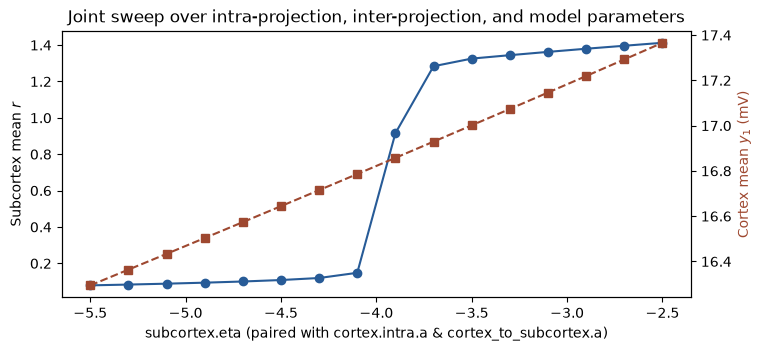

In [5]:
n_pts = 16
ic = [np.zeros((6, n_ctx, 1)), np.array([np.full((n_sub, 1), 0.1), np.full((n_sub, 1), -1.5)])]

res = nb.sweep(
    ns,
    nstep=800,
    initial_states=ic,
    **{
        "cortex.intra.a": np.linspace(0.005, 0.04, n_pts),
        "cortex_to_subcortex.a": np.linspace(0.1, 1.0, n_pts),
        "subcortex.eta": np.linspace(-5.5, -2.5, n_pts),
    },
)
assert res.sweep_values.shape == (n_pts, 3)
ctx_mean_y1 = res.squeezed("cortex")[:, 300:, 1, :].mean(axis=(1, 2))
sub_mean_r = res.squeezed("subcortex")[:, 300:, 0, :].mean(axis=(1, 2))
assert np.isfinite(ctx_mean_y1).all() and np.isfinite(sub_mean_r).all()

print(f"Completed {n_pts} joint sweep points in {res.elapsed*1e3:.1f} ms")
print("param_keys:", res.param_keys)

fig, ax1 = plt.subplots(figsize=(7.5, 3.4), layout="constrained")
ax1.plot(res.sweep_values[:, 2], sub_mean_r, "o-", color="#275b97", label="Subcortex mean $r$")
ax1.set(xlabel="subcortex.eta (paired with cortex.intra.a & cortex_to_subcortex.a)", ylabel="Subcortex mean $r$")
ax2 = ax1.twinx()
ax2.plot(res.sweep_values[:, 2], ctx_mean_y1, "s--", color="#9e4830", label="Cortex mean $y_1$")
ax2.set_ylabel("Cortex mean $y_1$ (mV)", color="#9e4830")
ax1.set_title("Joint sweep over intra-projection, inter-projection, and model parameters")
plt.show()

## Next steps

- [Bifurcation Sweeps](bifurcation.ipynb) — map 1D envelopes, 2D `grid=True` regime diagrams, and hysteresis branches.
- [Monte Carlo and Quasi-Monte Carlo Sweeps](mc-sampling.ipynb) — sample high-dimensional parameter spaces with `grid=False` and `monitor="features"`.
- [Hybrid Sweep Workflows and Performance](backends.ipynb) — end-to-end PSD and Balloon–Windkessel FC sweeps.